In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate our research project
project_root = Path.home() / "Documents" / "air-quality-retrieval-ai"

sys.path.insert(0, str(project_root))

from src.data_loader import load_air_quality_data

# Our loader uses a relative data directory
import os
os.chdir(project_root)

df = load_air_quality_data()

print("Dataset shape:", df.shape)
display(df.head())

Found 12 CSV files
Loading PRSA_Data_Aotizhongxin_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Changping_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dingling_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dongsi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Guanyuan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Gucheng_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Huairou_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Nongzhanguan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Shunyi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Tiantan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanliu_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanshouxigong_20130301-20170228.csv: 35064 rows
Dataset shape: (420768, 19)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


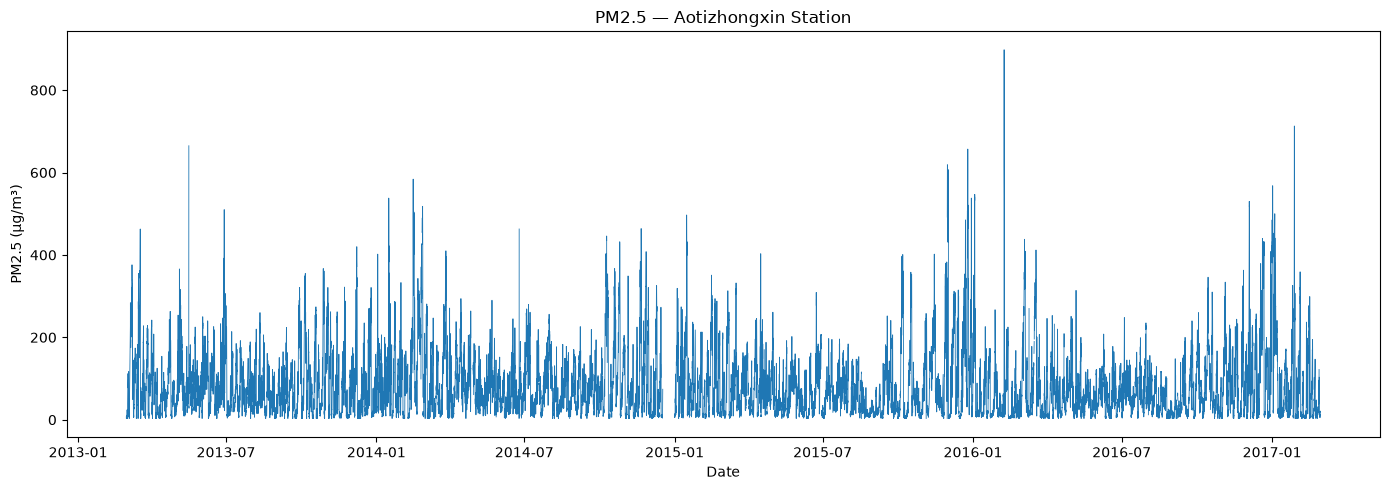

In [2]:
station_df = df[
    df["station"] == "Aotizhongxin"
].sort_values("datetime").copy()

plt.figure(figsize=(14, 5))

plt.plot(
    station_df["datetime"],
    station_df["PM2.5"],
    linewidth=0.6
)

plt.title("PM2.5 — Aotizhongxin Station")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

month
1      92.82
2      85.84
3     100.00
4      76.18
5      67.34
6      71.82
7      75.26
8      55.64
9      64.46
10     96.39
11     98.54
12    111.32
Name: PM2.5, dtype: float64


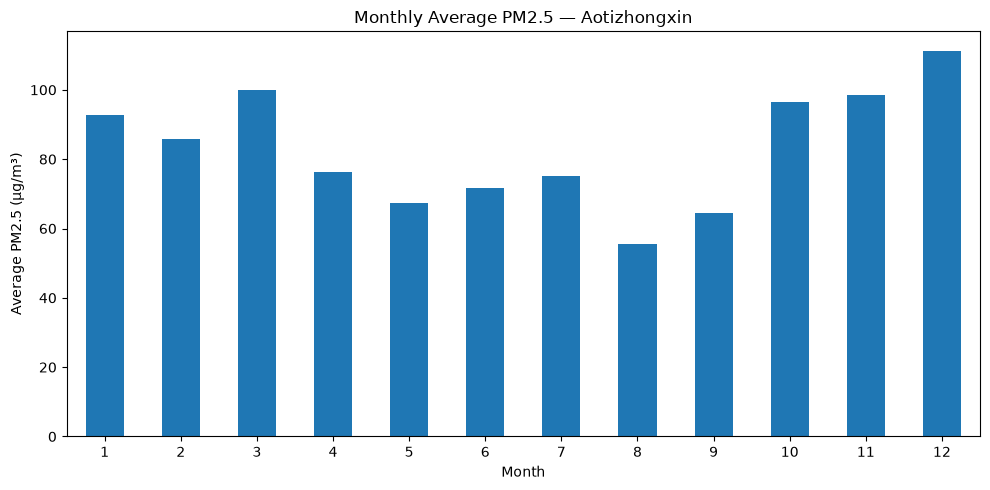

In [3]:
# Extract the calendar month
station_df["month"] = station_df["datetime"].dt.month

# Calculate average PM2.5 for each month
monthly_avg = (
    station_df.groupby("month")["PM2.5"]
    .mean()
)

print(monthly_avg.round(2))

# Visualize
plt.figure(figsize=(10, 5))

monthly_avg.plot(kind="bar")

plt.title("Monthly Average PM2.5 — Aotizhongxin")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

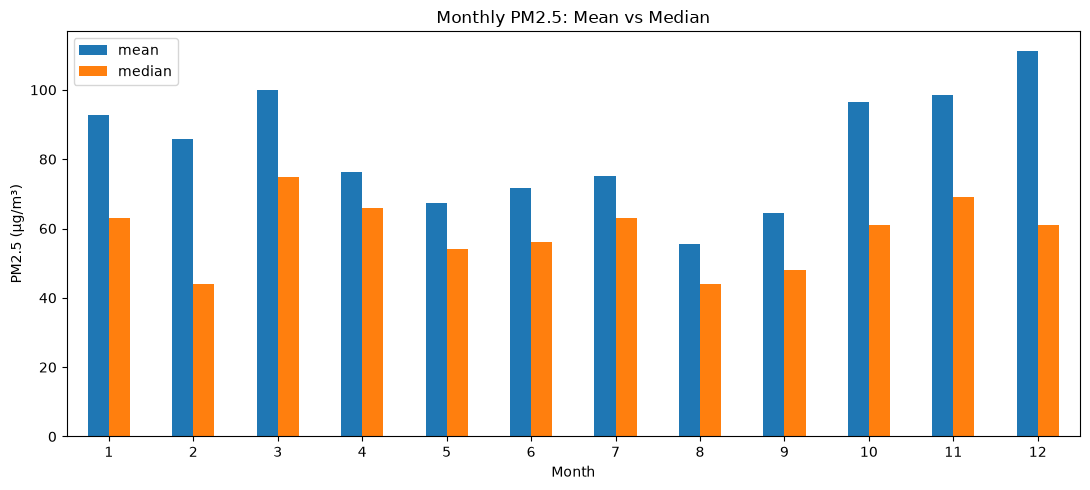

In [4]:
monthly_stats = (
    station_df.groupby("month")["PM2.5"]
    .agg(["mean", "median"])
)

monthly_stats.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Monthly PM2.5: Mean vs Median")
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Preliminary Findings: Monthly PM2.5 Patterns

**Research question:** How do PM2.5 concentrations vary by calendar month at the Aotizhongxin monitoring station?

**Finding 1 — Monthly variation:** The highest monthly mean PM2.5 concentration occurs in December (111.32 µg/m³), while the lowest occurs in August (55.64 µg/m³). This suggests a seasonal component that may be useful for forecasting.

**Finding 2 — Distribution asymmetry:** The monthly mean exceeds the median in every month, indicating positively skewed pollutant distributions. Extreme pollution observations may contribute substantially to monthly averages.

**Implication for forecasting:** Calendar-based features, including month and season, are candidates for future predictive models. Model performance should also be evaluated during high-pollution episodes.

**Limitations:** These findings are based on one monitoring station and monthly averages pooled across several years. They do not establish causation or demonstrate that the seasonal pattern is consistent across stations and years.

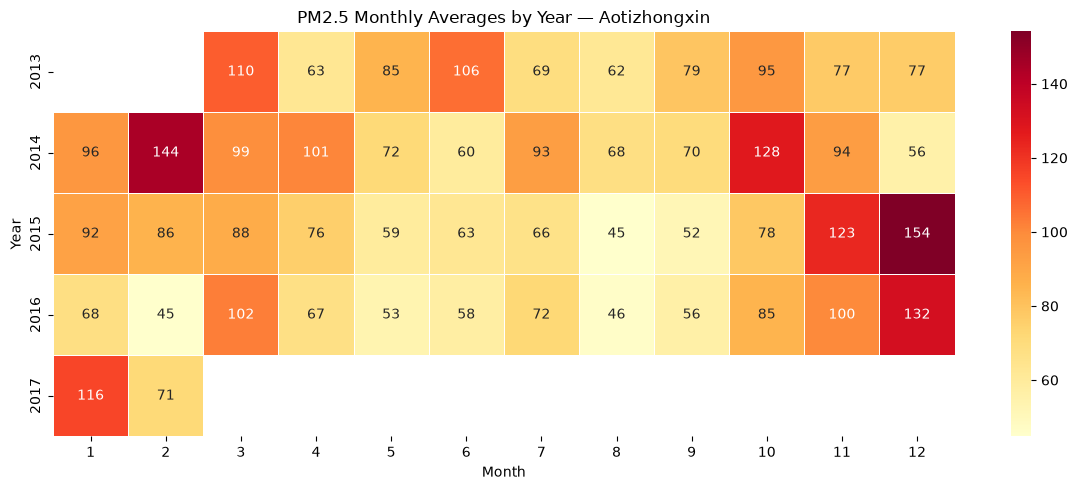

In [5]:
import seaborn as sns

# Create year and month features
station_df["year"] = station_df["datetime"].dt.year
station_df["month"] = station_df["datetime"].dt.month

# Calculate monthly average for each year
year_month = (
    station_df.groupby(["year", "month"])["PM2.5"]
    .mean()
    .unstack()
)

# Create heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    year_month,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("PM2.5 Monthly Averages by Year — Aotizhongxin")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [6]:
# Define seasons using calendar months
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

station_df["season"] = station_df["month"].map(season_map)

season_stats = (
    station_df.groupby("season")["PM2.5"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

display(season_stats.round(2))

,count,mean,median,std
season,,,,
Winter,8226,96.42,56.0,108.56
Spring,8619,81.23,63.0,70.78
Summer,8664,67.55,54.0,52.95
Autumn,8630,86.59,59.0,84.92


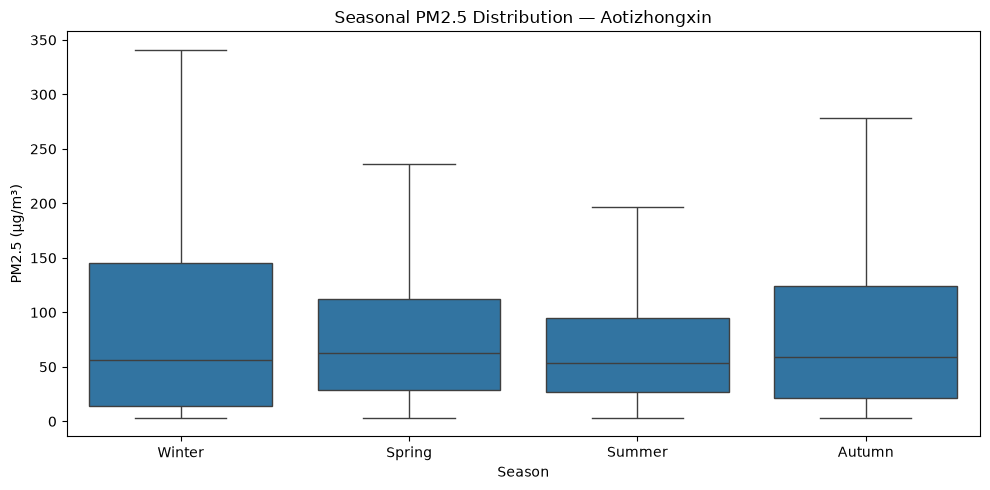

In [7]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=station_df,
    x="season",
    y="PM2.5",
    order=["Winter", "Spring", "Summer", "Autumn"],
    showfliers=False
)

plt.title("Seasonal PM2.5 Distribution — Aotizhongxin")
plt.xlabel("Season")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

### Finding 3 — Interannual Variability in PM2.5

The year-by-month heatmap indicates that the seasonal distribution of PM2.5 is not identical across years. High monthly averages occur during several winter and early-spring periods, while some warmer months exhibit comparatively lower concentrations.

For example, December's monthly mean varies substantially between 2014 (approximately 56 µg/m³) and 2015 (approximately 154 µg/m³).

**Research implication:** Calendar-based features may improve forecasting, but seasonal patterns alone are unlikely to capture the full variability of air pollution. Historical pollutant measurements and meteorological variables should also be investigated.

**Limitation:** These findings are descriptive, based on Aotizhongxin station, and do not establish causal relationships.

### Finding 4 — Seasonal Differences in PM2.5 Concentration and Variability

Seasonal descriptive statistics at the Aotizhongxin monitoring station reveal differences in PM2.5 concentration and variability.

Winter has the highest mean concentration (96.42 µg/m³) and standard deviation (108.56 µg/m³), while summer has the lowest mean (67.55 µg/m³) and standard deviation (52.95 µg/m³).

Interestingly, spring has the highest median concentration (63 µg/m³), whereas winter has the highest mean. This suggests that elevated pollution observations contribute more strongly to winter's average concentration.

**Research implication:** Forecasting models should be evaluated across different seasons and pollution regimes. In particular, performance during periods of high variability may differ from performance under typical conditions.

**Limitation:** The analysis is descriptive and limited to one monitoring station. Seasonal differences do not establish their underlying causes, and observations within the time series are not statistically independent.

In [8]:
# Keep rows where both variables are available
wind_data = station_df[
    ["PM2.5", "WSPM"]
].dropna()

# Pearson correlation
correlation = wind_data["PM2.5"].corr(
    wind_data["WSPM"]
)

print("PM2.5 vs Wind Speed")
print(f"Pearson correlation: {correlation:.3f}")
print(f"Valid observations: {len(wind_data):,}")

PM2.5 vs Wind Speed
Pearson correlation: -0.279
Valid observations: 34,125


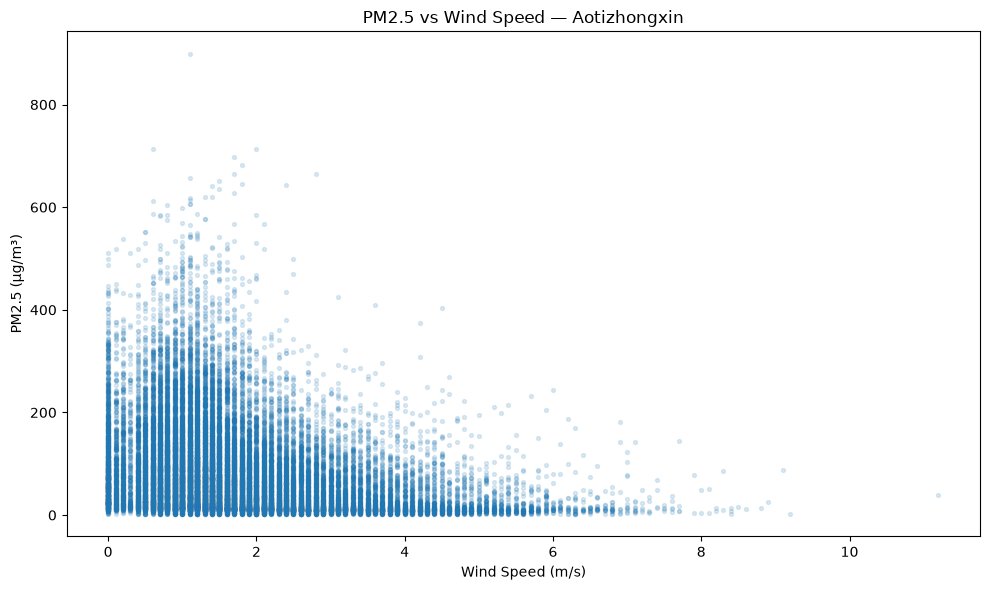

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    wind_data["WSPM"],
    wind_data["PM2.5"],
    alpha=0.15,
    s=8
)

plt.title("PM2.5 vs Wind Speed — Aotizhongxin")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

In [10]:
seasonal_correlations = (
    station_df.groupby("season")
    .apply(
        lambda group: group["PM2.5"].corr(
            group["WSPM"]
        ),
        include_groups=False
    )
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

print("Seasonal correlations:")
print(seasonal_correlations.round(3))

Seasonal correlations:
season
Winter   -0.390
Spring   -0.267
Summer   -0.111
Autumn   -0.320
dtype: float64


### Finding 5 — Association Between Wind Speed and PM2.5

The relationship between PM2.5 concentration and wind speed was examined using 34,125 paired observations from the Aotizhongxin monitoring station.

The overall Pearson correlation coefficient was −0.279, indicating a negative linear association. Scatterplot analysis showed that high PM2.5 concentrations occurred predominantly at lower wind speeds.

Seasonal analysis revealed differences in correlation strength: winter (−0.390), spring (−0.267), summer (−0.111), and autumn (−0.320).

**Research implication:** Wind speed may be a useful predictor of PM2.5 concentration. Seasonal variation in the observed association motivates testing whether interactions between weather variables and calendar-based features improve forecasting performance.

**Limitations:** Correlation does not establish causation, and the results may be influenced by other meteorological conditions, temporal dependence, and differences between monitoring stations.

In [11]:
print(df.shape)
print(df["station"].nunique())

(420768, 19)
12


## Multi-Station Air Quality Analysis

In [12]:
station_stats = (
    df.groupby("station")["PM2.5"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .sort_values("mean", ascending=False)
)

display(station_stats.round(2))

,count,mean,median,std,min,max
station,,,,,,
Dongsi,34314,86.19,61.0,86.58,3.0,737.0
Wanshouxigong,34368,85.02,60.0,85.98,3.0,999.0
Nongzhanguan,34436,84.84,59.0,86.23,2.0,844.0
Gucheng,34418,83.85,60.0,82.80,2.0,770.0
Wanliu,34682,83.37,59.0,81.91,2.0,957.0
Guanyuan,34448,82.93,59.0,80.93,2.0,680.0
Aotizhongxin,34139,82.77,58.0,82.14,3.0,898.0
Tiantan,34387,82.16,59.0,80.92,3.0,821.0
Shunyi,34151,79.49,55.0,81.23,2.0,941.0


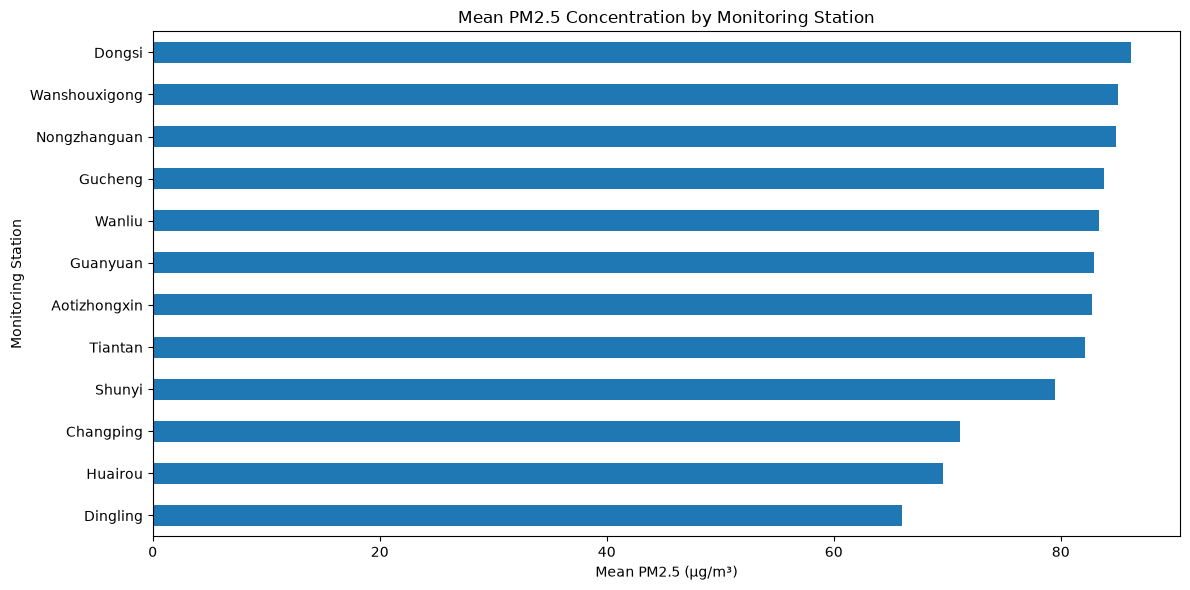

In [13]:
plt.figure(figsize=(12, 6))

station_stats["mean"].sort_values().plot(
    kind="barh"
)

plt.title("Mean PM2.5 Concentration by Monitoring Station")
plt.xlabel("Mean PM2.5 (µg/m³)")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()

In [14]:
missing_by_station = (
    df.groupby("station")["PM2.5"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

print("Missing PM2.5 percentage by station:")
display(missing_by_station.round(2))

Missing PM2.5 percentage by station:


station
Huairou          2.72
Aotizhongxin     2.64
Shunyi           2.60
Dingling         2.22
Changping        2.21
Dongsi           2.14
Wanshouxigong    1.98
Tiantan          1.93
Gucheng          1.84
Nongzhanguan     1.79
Guanyuan         1.76
Wanliu           1.09
Name: PM2.5, dtype: float64

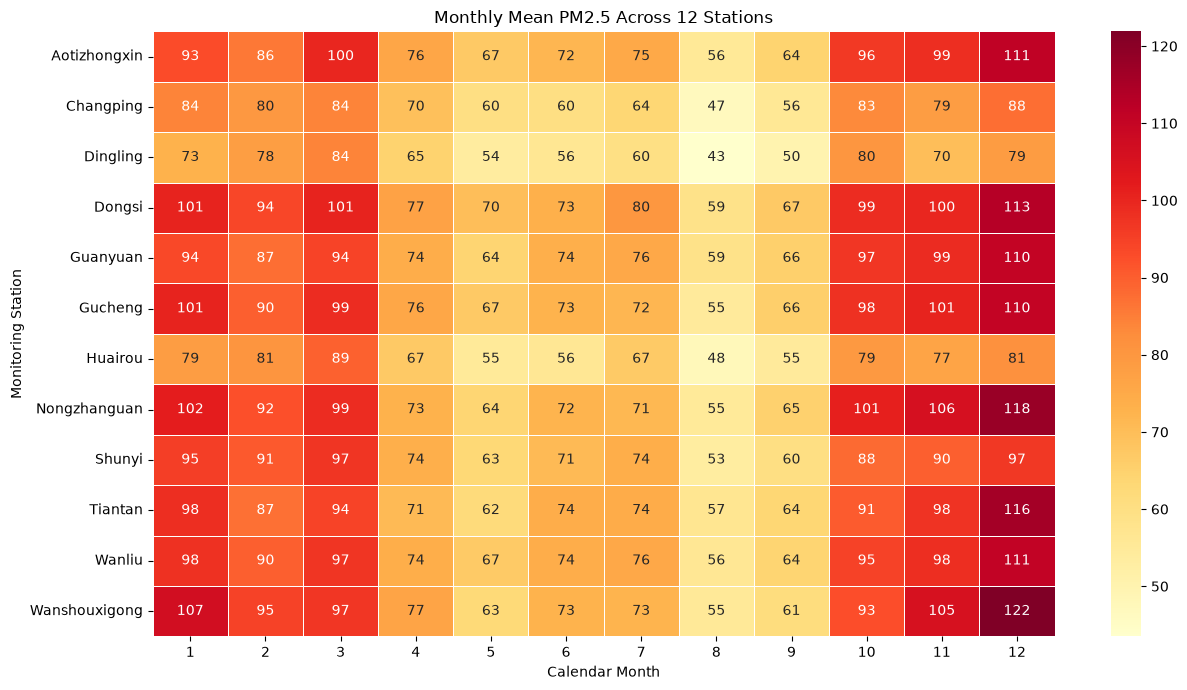

In [15]:
# Extract calendar month
df["month_num"] = df["datetime"].dt.month

# Calculate mean PM2.5 by station and month
station_month = (
    df.groupby(["station", "month_num"])["PM2.5"]
    .mean()
    .unstack()
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    station_month,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.4
)

plt.title("Monthly Mean PM2.5 Across 12 Stations")
plt.xlabel("Calendar Month")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()

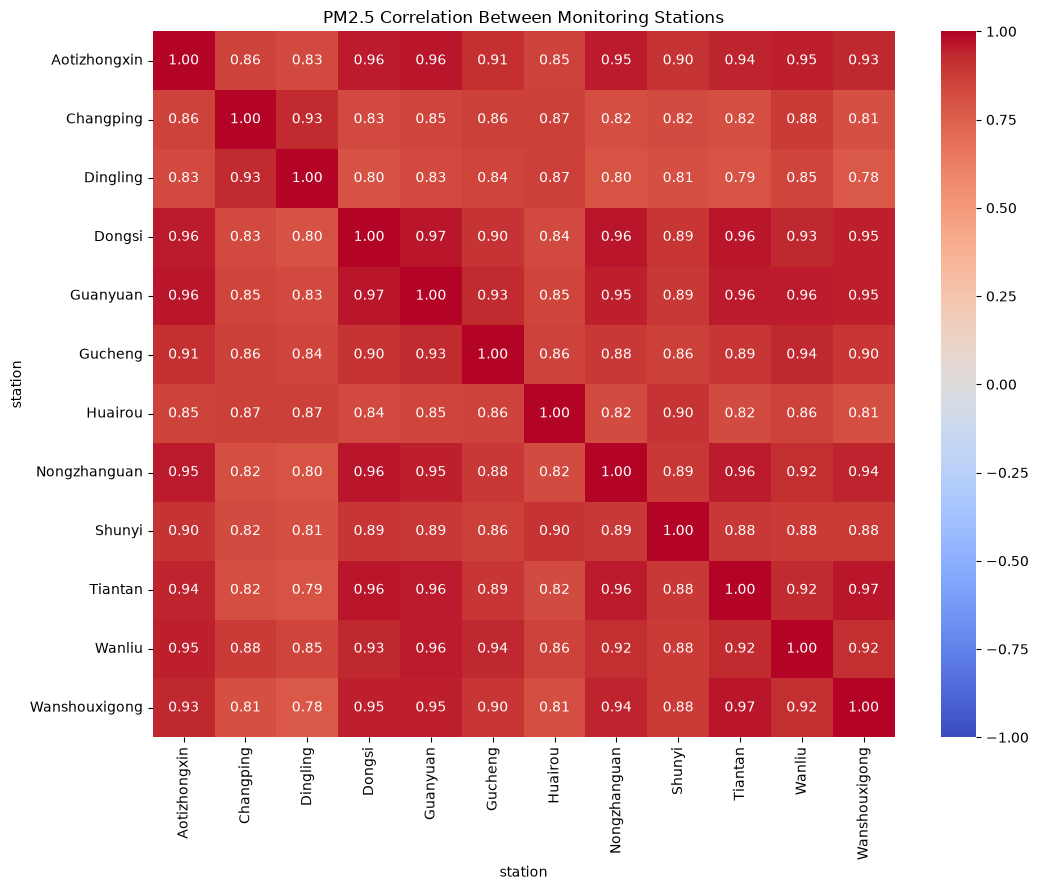

In [16]:
# Convert long-form measurements to wide format
wide_pm25 = df.pivot(
    index="datetime",
    columns="station",
    values="PM2.5"
)

# Calculate pairwise Pearson correlations
station_corr = wide_pm25.corr()

plt.figure(figsize=(11, 9))

sns.heatmap(
    station_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("PM2.5 Correlation Between Monitoring Stations")

plt.tight_layout()
plt.show()

### Multi-Station Exploratory Analysis — Preliminary Findings

**Research objective:** Examine whether PM2.5 concentration levels, seasonal patterns and temporal behavior differ across Beijing's 12 monitoring stations.

**Finding 1 — Station-level differences:**
[Record which stations have the highest and lowest mean and median PM2.5 concentrations.]

**Finding 2 — Data completeness:**
[Identify the stations with the highest missing PM2.5 percentages.]

**Finding 3 — Seasonal similarities:**
[Describe whether high-pollution months are similar across stations.]

**Finding 4 — Cross-station relationships:**
[Identify the strongest and weakest station correlations.]

**Implications for forecasting:** These findings will help motivate experiments comparing station-specific forecasting with pooled and retrieval-augmented methods.

**Limitations:** The analysis is descriptive. Correlations do not establish causal relationships, and no forecasting performance improvements have yet been demonstrated.

### Finding 6 — Multi-Station PM2.5 Characteristics

**Research objective:** Investigate spatial differences, seasonal similarities, data completeness, and temporal correlations across 12 air-quality monitoring stations in Beijing.

**Station-level differences:** Dongsi has the highest mean PM2.5 concentration (86.19 µg/m³), while Dingling has the lowest (65.99 µg/m³). Their median concentrations also differ (61 and 41 µg/m³, respectively).

**Data completeness:** Missing PM2.5 measurements range from 1.09% at Wanliu to 2.72% at Huairou.

**Seasonal patterns:** Stations exhibit broadly similar seasonal behavior, with relatively low average concentrations in August and higher concentrations during several colder months.

**Cross-station relationships:** Hourly PM2.5 measurements are strongly positively correlated across monitoring stations. Displayed pairwise correlations range from approximately 0.78 to 0.97.

**Research implications:** The observed similarities motivate evaluating whether historical measurements from multiple stations can improve forecasting compared with station-specific baselines.

**Limitations:** These results are descriptive. Strong contemporaneous correlations do not establish predictive value, causation, or improvements from retrieval augmentation. These hypotheses require leakage-safe forecasting experiments.